# Л3 — Рішення з ціною помилки

Модель класифікації дає ймовірність події, наприклад відмови обладнання. Щоб із цього вийшло рішення — висилати бригаду чи ні, — модель має вчитися на чесних даних, а поріг має враховувати ціну кожної помилки.

Ноутбук нижче проходить цей шлях на одній задачі, спрощено. Більше туторіалів — у [Kaggle Learn](https://www.kaggle.com/learn), зокрема [Intro to Machine Learning](https://www.kaggle.com/learn/intro-to-machine-learning) та [Intermediate Machine Learning](https://www.kaggle.com/learn/intermediate-machine-learning) з уроками про витік даних, pipelines і крос-валідацію.

Типовий шлях задачі класифікації (у дужках — кроки цього ноутбука):

- зрозуміти дані (1);
- перевірити, чи дані чесні: витік, зміщена вибірка, data drift (2–4);
- підготувати ознаки: кодування категорій, масштабування (5). У реальних проєктах ці перетворення збирають у pipeline, щоб до нових даних застосовувались ті самі кроки; тут вони написані вручну;
- розділити дані на навчальну й валідаційну частини (5). Часто замість однієї валідаційної частини беруть крос-валідацію; тут її немає;
- порівняти кілька моделей (6);
- підібрати гіперпараметри (7). Зазвичай це перебір за сіткою з крос-валідацією (`GridSearchCV`); тут лише одна крива для `alpha`;
- обрати поріг рішення під задачу (8);
- застосувати модель до нових даних (9) і далі стежити, чи не погіршилась вона з часом.

І головне: гарна метрика на валідації ще не гарантує, що модель працюватиме на нових даних. Якщо в даних є витік, зміщення чи зсув, модель виглядатиме добре, а рішення будуть поганими.

Інші часті проблеми даних, про які варто пам'ятати:

- **незбалансовані класи** — подія рідкісна, і частка правильних відповідей оманлива. Тут відмов 5–9%, тому моделі порівнюють за PR-AUC (крок 6);
- **замало даних** — модель запам'ятовує навчальні приклади замість закономірності; близьке явище видно на кривій перенавчання (крок 7);
- **пропуски й помилки в даних** — Л1;
- **помилки в мітках** — частину об'єктів позначено неправильно, і модель вчиться на цих помилках; тут цього немає;
- **зв'язок без причини** — ознака пов'язана з ціллю через третій чинник, а не напряму; Л2.

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Опис даних, вартості й таблиця пасток — у `README.md`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

## 1. Завантаження даних

Спершу подивіться, що всередині файлів: розмірність, колонки, типи й частку відмов у `train`. Можуть допомогти `df.head()`, `df.shape` і `df.dtypes`.

Вартості свого варіанта впишіть із таблиці в `README.md`: від них залежить правило рішення в кроці 8.

In [3]:
COST_VISIT = 2750
COST_FAILURE = 50000

# TODO: завантажте registry.csv, train.csv і test.csv свого варіанта з папки variants/<варіант>/ і виведіть частку failed у train
registry = pd.read_csv("registry.csv")
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("registry shape: ", registry.shape)
print("train shape: ", train.shape)
print("test shape: ", test.shape)

display("registry head:", registry.head())
display("train head:", train.head())
display("test head:", test.head())

print("registry types:\n", registry.dtypes)
print("train types:\n", train.dtypes)
print("test types:\n", test.dtypes)

failure = train["failed"].mean()
total_failures = train["failed"].value_counts()

print(f"Failure percent: {(failure*100):.3f}%")
print("total failures")
print(total_failures)

registry shape:  (6000, 8)
train shape:  (4015, 21)
test shape:  (1985, 20)


'registry head:'

,object_id,cohort,equipment_type,voltage_class,region,install_year,last_overhaul_year,outdoor
0,EQ100001,current,meter_unit,kv10,north,2001,2022,0
1,EQ100002,history,switchgear,kv10,west,1993,2020,1
2,EQ100003,history,meter_unit,kv6,south,2005,2020,0
3,EQ100004,current,switchgear,kv6,south,1995,2024,0
4,EQ100005,history,transformer,kv6,south,1998,2025,1


'train head:'

,object_id,load_mean,load_std,load_stability,load_weekend_ratio,temp_rise_mean,temp_rise_std,temp_rise_median,pd_mean,pd_std,...,pd_per_load,temp_per_load,equipment_type,voltage_class,region,install_year,last_overhaul_year,outdoor,failed,work_order_opened
0,EQ100002,56.221,6.815,0.8919,0.8025,11.841,0.731,11.965,13.816,2.439,...,0.2457,0.2106,switchgear,kv10,west,1993,2020,1,0,0
1,EQ100003,40.115,4.879,0.8916,0.7952,12.818,0.882,12.740,35.198,6.664,...,0.8774,0.3195,meter_unit,kv6,south,2005,2020,0,0,0
2,EQ100005,55.410,6.533,0.8945,0.7951,27.541,2.563,28.060,180.804,31.961,...,3.2630,0.4970,transformer,kv6,south,1998,2025,1,0,0
3,EQ100007,84.614,10.346,0.8911,0.8043,10.397,0.715,10.455,16.292,3.361,...,0.1925,0.1229,transformer,kv10,north,2005,2018,1,0,0
4,EQ100009,81.535,8.561,0.9050,0.8271,19.843,1.656,20.030,30.664,5.468,...,0.3761,0.2434,transformer,kv6,south,1986,2023,1,0,0


'test head:'

,object_id,load_mean,load_std,load_stability,load_weekend_ratio,temp_rise_mean,temp_rise_std,temp_rise_median,pd_mean,pd_std,pd_stability,pd_per_load,temp_per_load,equipment_type,voltage_class,region,install_year,last_overhaul_year,outdoor,work_order_opened
0,EQ100001,35.401,4.126,0.8956,0.8222,10.343,0.537,10.335,32.416,6.591,0.8310,0.9157,0.2922,meter_unit,kv10,north,2001,2022,0,0
1,EQ100004,37.102,5.438,0.8722,0.7561,12.630,0.771,12.665,27.772,5.881,0.8252,0.7485,0.3404,switchgear,kv6,south,1995,2024,0,0
2,EQ100006,50.188,6.626,0.8834,0.7954,11.535,0.756,11.635,31.041,5.876,0.8408,0.6185,0.2298,switchgear,kv6,centre,1986,2017,0,0
3,EQ100008,30.077,3.795,0.8880,0.7739,9.632,0.575,9.670,22.166,3.833,0.8526,0.7370,0.3202,meter_unit,kv10,centre,1993,2016,0,0
4,EQ100012,51.821,6.096,0.8948,0.8092,31.763,2.529,32.075,139.036,27.158,0.8366,2.6830,0.6129,transformer,kv10,west,1992,2022,0,0


registry types:
 object_id               str
cohort                  str
equipment_type          str
voltage_class           str
region                  str
install_year          int64
last_overhaul_year    int64
outdoor               int64
dtype: object
train types:
 object_id                 str
load_mean             float64
load_std              float64
load_stability        float64
load_weekend_ratio    float64
temp_rise_mean        float64
temp_rise_std         float64
temp_rise_median      float64
pd_mean               float64
pd_std                float64
pd_stability          float64
pd_per_load           float64
temp_per_load         float64
equipment_type            str
voltage_class             str
region                    str
install_year            int64
last_overhaul_year      int64
outdoor                 int64
failed                  int64
work_order_opened       int64
dtype: object
test types:
 object_id                 str
load_mean             float64
load_std      

## 2. Витік (M-1)

Витік (data leakage) — колонка, значення якої стає відомим лише після того, що ми хочемо передбачити. Наприклад, у даних про відмови може бути колонка «вартість ремонту». Вона дуже точно «передбачає» відмову: ремонтують саме те, що зламалося. Але вартість ремонту з'являється вже після відмови, а рішення ухвалюють раніше, коли об'єкт ще працює й цього значення немає. Модель, навчена на такій колонці, на навчальних даних виглядає чудово, а на нових об'єктах не працює. Такі колонки прибирають.

Не завжди відомо, коли заповнюють кожну колонку, тож витік шукають за ознакою «надто добре вгадує». Для кожної колонки окремо рахують **ROC AUC** — ймовірність того, що у випадкового об'єкта, який відмовив, значення колонки більше, ніж у випадкового справного. 0.5 — колонка не відрізняє їх зовсім, як підкидання монети; 1 — відрізняє ідеально. Звичайна ознака на кшталт температури чи навантаження так точно не вгадує. Колонку з AUC понад 0.9 тут вважають витоком. У реальному проєкті висока AUC — привід з'ясувати, коли колонку заповнюють.

1. Для кожної числової колонки `train`, крім `failed`, порахуйте `roc_auc_score(train["failed"], колонка)`. Якщо AUC менше 0.5, візьміть 1 − AUC: колонка пов'язана з відмовою навпаки, у тих, що відмовили, значення менші.
2. Виведіть AUC усіх колонок від більшого до меншого.
3. Колонки з AUC більше 0.9 приберіть із `train` і `test`.

Можуть допомогти `select_dtypes("number")`, `sort_values` і `drop(columns=...)`.

In [4]:
# TODO: M-1
train_columns_auc = train.select_dtypes("number").columns.drop("failed")


results = []

for column in train_columns_auc:
    auc = roc_auc_score(train["failed"], train[column])
    if auc < 0.5: 
        auc_adj = 1 - auc
    else: auc_adj = auc

    results.append({"column": column,
                    "roc_auc": auc,
                    "roc_auc_adj": auc_adj
                    })

df_auc = pd.DataFrame(results)
df_auc = df_auc.sort_values("roc_auc_adj", ascending=False)

display(df_auc.round(3))

leak = df_auc.loc[df_auc["roc_auc_adj"] > 0.9]

leak = leak["column"].tolist()
print(leak)

train = train.drop(columns=leak)
test = test.drop(columns=leak)
display("train head:", train.head())
display("test head:", test.head())

,column,roc_auc,roc_auc_adj
15,work_order_opened,0.977,0.977
5,temp_rise_std,0.803,0.803
6,temp_rise_median,0.799,0.799
4,temp_rise_mean,0.799,0.799
7,pd_mean,0.768,0.768
8,pd_std,0.764,0.764
11,temp_per_load,0.711,0.711
10,pd_per_load,0.667,0.667
1,load_std,0.597,0.597
0,load_mean,0.597,0.597


['work_order_opened']


'train head:'

,object_id,load_mean,load_std,load_stability,load_weekend_ratio,temp_rise_mean,temp_rise_std,temp_rise_median,pd_mean,pd_std,pd_stability,pd_per_load,temp_per_load,equipment_type,voltage_class,region,install_year,last_overhaul_year,outdoor,failed
0,EQ100002,56.221,6.815,0.8919,0.8025,11.841,0.731,11.965,13.816,2.439,0.8499,0.2457,0.2106,switchgear,kv10,west,1993,2020,1,0
1,EQ100003,40.115,4.879,0.8916,0.7952,12.818,0.882,12.740,35.198,6.664,0.8408,0.8774,0.3195,meter_unit,kv6,south,2005,2020,0,0
2,EQ100005,55.410,6.533,0.8945,0.7951,27.541,2.563,28.060,180.804,31.961,0.8498,3.2630,0.4970,transformer,kv6,south,1998,2025,1,0
3,EQ100007,84.614,10.346,0.8911,0.8043,10.397,0.715,10.455,16.292,3.361,0.8290,0.1925,0.1229,transformer,kv10,north,2005,2018,1,0
4,EQ100009,81.535,8.561,0.9050,0.8271,19.843,1.656,20.030,30.664,5.468,0.8487,0.3761,0.2434,transformer,kv6,south,1986,2023,1,0


'test head:'

,object_id,load_mean,load_std,load_stability,load_weekend_ratio,temp_rise_mean,temp_rise_std,temp_rise_median,pd_mean,pd_std,pd_stability,pd_per_load,temp_per_load,equipment_type,voltage_class,region,install_year,last_overhaul_year,outdoor
0,EQ100001,35.401,4.126,0.8956,0.8222,10.343,0.537,10.335,32.416,6.591,0.8310,0.9157,0.2922,meter_unit,kv10,north,2001,2022,0
1,EQ100004,37.102,5.438,0.8722,0.7561,12.630,0.771,12.665,27.772,5.881,0.8252,0.7485,0.3404,switchgear,kv6,south,1995,2024,0
2,EQ100006,50.188,6.626,0.8834,0.7954,11.535,0.756,11.635,31.041,5.876,0.8408,0.6185,0.2298,switchgear,kv6,centre,1986,2017,0
3,EQ100008,30.077,3.795,0.8880,0.7739,9.632,0.575,9.670,22.166,3.833,0.8526,0.7370,0.3202,meter_unit,kv10,centre,1993,2016,0
4,EQ100012,51.821,6.096,0.8948,0.8092,31.763,2.529,32.075,139.036,27.158,0.8366,2.6830,0.6129,transformer,kv10,west,1992,2022,0


## 3. Зміщена вибірка (M-2)

Завжди треба враховувати, як збирали дані. Наприклад, лікарня має дані переважно про людей, які прийшли з підозрою на хворобу: здорові приходять туди набагато рідше. Тож хворих у таких даних набагато більше, ніж серед усіх людей. Таке зміщення вибірки (selection bias) буває й в інших задачах: результат відомий не для всіх об'єктів, а переважно для тих, що вже викликали підозру.

Модель на таких даних усе ще може навчитися відрізняти ризикові об'єкти від решти. Але числа, пораховані на зміщеній вибірці, — частку подій, точність, ефект рішення — не можна переносити на всі об'єкти: вони будуть спотворені.

У цій задачі `registry.csv` містить усі об'єкти, а `train.csv` — лише ті об'єкти `history`, для яких відомо, чи вони відмовили.

Поділіть кількість рядків `train` на кількість об'єктів `registry` з `cohort == "history"` і виведіть частку; менше 0.9 — вибірка зміщена. Тоді виведіть ще середній `install_year` об'єктів `history`, що є в `train`, і об'єктів `history`, яких у `train` немає. Може допомогти `isin`.

У коді після цього нічого не змінюється: рішення будується так само, але частку відмов і ефект на валідації не можна переносити на всі об'єкти.

In [5]:
# TODO: M-2
history = registry[registry['cohort'] == "history"]

part = len(train) / len(history)

print("Частка:", part)
print("count train: ", len(train))
print("count history: ", len(history))

train_ids = train["object_id"]

print("mean install year in train history", history[
                                                    history["object_id"].isin(train_ids)
                                                    ]["install_year"].mean())
print("mean install year not in train history", history[
                                                        ~history["object_id"].isin(train_ids)
                                                        ]["install_year"].mean())

Частка: 1.0
count train:  4015
count history:  4015
mean install year in train history 1999.0702366127023
mean install year not in train history nan


## 4. Зсув у часі (M-3)

Властивості об'єктів змінюються з часом: люди старішають, обладнання зношується, датчик після калібрування чи заміни починає показувати інакше. Тому дані різних періодів можуть відрізнятися. Це називають **data drift** (зсув даних). Коли ж змінюється сам зв'язок ознак із ціллю, це **concept drift**; тут його немає.

Проблема виникає, коли зсув не врахували. Модель вивчила, що звичайна температура — 40 °C, а в нових даних датчик показує 45 °C для таких самих об'єктів. Модель побачить «гарячіші» об'єкти й помилятиметься, хоча нічого не змінилося.

**Як помітити:** порівняти розподіл ознак у навчальних і нових даних — середні, гістограми. Тут зсув середнього міряють у стандартних відхиленнях train: 0.5 — половина звичайного розкиду між об'єктами. Зсув рахують зі знаком: від'ємний означає, що в нових даних значення нижчі.

**Як боротися** — залежить від причини:

- **змінилася шкала вимірювання** (калібрування, інший датчик), а об'єкти ті самі — ознаки зводять до однієї шкали, наприклад стандартизують окремо в кожному періоді. Середнє стає 0, відхилення 1, а порядок об'єктів — хто гарячіший за кого — лишається;
- **змінилися самі об'єкти** — таке вирівнювання стерло б справжні зміни. Тоді модель перенавчають на свіжих даних і регулярно перевіряють її якість.

У цій задачі `train.csv` описує перший період, `test.csv` — другий. Якщо зсув є, він — у шкалі температурного датчика, тож підходить перший спосіб.

1. Виведіть зсув зі знаком: (середнє `temp_rise_mean` у test − середнє в train) / стандартне відхилення `temp_rise_mean` у train. Відхилення — `.std()` з pandas.
2. Якщо зсув більший за 0.5, стандартизуйте колонки `temp`: у train — середнім і відхиленням train, у test — середнім і відхиленням test. Якщо стандартизувати test за train, зсув лишиться.

In [9]:
temp = ["temp_rise_mean", "temp_rise_std", "temp_rise_median", "temp_per_load"]

# TODO: M-3 — зсув і, якщо він більший за 0.5, стандартизація temp окремо в train і в test
train_temp_rise_mean = train["temp_rise_mean"].mean()
test_temp_rise_mean = test["temp_rise_mean"].mean()

train_std = train["temp_rise_mean"].std()

drift = (test_temp_rise_mean - train_temp_rise_mean)/train_std

print("mean temp train:", train_temp_rise_mean.round(3))
print("mean temp test:", test_temp_rise_mean.round(3))
print("std temp train:", train_std.round(3))

print("drift:", drift.round(3))

mean temp train: 15.876
mean temp test: 16.014
std temp train: 5.878
drift: 0.023


## 5. Ознаки й поділ

Моделі працюють із числами, тому категорійні колонки кодують **one-hot**: окрема колонка 0/1 на кожне значення. Порядкових номерів категоріям не дають, бо `north` не «більше» за `south`.

**Валідаційна частина.** Щоб зрозуміти, як модель працюватиме на нових об'єктах, її перевіряють на даних, яких вона не бачила під час навчання. Для цього частину `train` відкладають убік — це валідаційна частина. На ній і порівнюють моделі: модель, що просто запам'ятала навчальні об'єкти, на навчальних даних виглядатиме ідеально, а на валідаційних — ні.

Валідаційна частина має бути схожою на дані, до яких модель застосовуватимуть. Відмови рідкісні, тож при випадковому поділі частка відмов у ній може помітно відрізнятися від навчальної, а в малому наборі даних відмов там може не виявитися зовсім, і оцінити модель стане неможливо. `stratify=y` зберігає однакову частку відмов в обох частинах.

**Масштабування.** Ознаки мають різні одиниці й розміри: `load_mean` — від 15 до 148 А, а `load_stability` — від 0.85 до 0.91. Метод опорних векторів, найближчі сусіди й перцептрон рахують відстані чи зважені суми, тож для них різниця навантаження в 100 переважить різницю стабільності в 0.05, навіть якщо стабільність важливіша. Тому ознаки стандартизують: середнє 0, стандартне відхилення 1. Дереву рішень і наївному Баєсу масштаб не заважає. Середні й відхилення беруть лише з навчальної частини: якщо взяти їх з усіх даних, валідаційна частина вплине на навчання — це теж витік, як у кроці 2.

1. Зберіть ознаки через `pd.get_dummies(..., columns=categorical, dtype=float)`: `X` — з `train` без `object_id` і `failed`, `X_test` — з `test` без `object_id`. Колонки `X_test` мають іти в тому самому порядку, що в `X`: `X_test[X.columns]`.
2. `y` — колонка `failed`.
3. Поділ і стандартизацію задано нижче: `StandardScaler` навчається лише на `X_tr` і тим самим перетворенням застосовується до `X_va` і `X_test`.

In [ ]:
categorical = ["equipment_type", "voltage_class", "region"]

# TODO: X, X_test і y
X = pd.get_dummies(train.drop(columns=["object_id", "failed"]), columns=categorical, dtype=float)
X_test = pd.get_dummies(test.drop(columns=["object_id"]), columns=categorical, dtype=float)
y = train["failed"]

# display("X", X)
# display("X_test", X_test)

X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

scaler = StandardScaler().fit(X_tr)
X_tr, X_va, X_te = scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_test)


X_tr (3011, 25)
X_va (1004, 25)
X_te (1985, 25)


## 6. П'ять моделей

**Як порівнювати.** Звична метрика — **accuracy**, частка правильних відповідей. При рідкісних подіях вона оманлива: якщо відмов 8%, модель, яка завжди каже «не відмовить», має accuracy 92%, але не знаходить жодної відмови.

Тому тут порівнюють інакше. Модель упорядковує об'єкти від найризикованішого до найспокійнішого. Якщо брати об'єкти згори списку, можна рахувати **precision** — яка частка взятих справді відмовила, і **recall** — яку частку всіх відмов уже знайдено. **PR-AUC** (`average_precision_score`) — середня precision, поки список росте від першої знайденої відмови до останньої. 1 — усі відмови стоять на самому верху списку; якщо порядок випадковий, PR-AUC дорівнює частці відмов. Тому PR-AUC завжди порівнюють із часткою відмов.

| Модель | Як оцінює ймовірність відмови |
|---|---|
| дерево рішень | ділить об'єкти порогами ознак; ймовірність — частка відмов у листку. `max_depth` обмежує кількість поділів |
| метод опорних векторів | шукає межу з найширшим проміжком між класами; сам дає лише відстань до межі, а `CalibratedClassifierCV` перетворює її на ймовірність |
| найближчі сусіди | частка відмов серед `n_neighbors` найближчих об'єктів навчальної частини |
| наївний Баєс | формула Баєса за припущення, що ознаки незалежні |
| багатошаровий перцептрон | прихований шар із 32 нейронів: кожен зважує ознаки й пропускає суму через функцію активації ReLU; вихідний нейрон дає ймовірність. Ваги підбирає зворотне поширення помилки, `alpha` — штраф за великі ваги |

Якщо навчальна PR-AUC набагато вища за валідаційну, модель запам'ятала навчальні об'єкти, а не навчилася розпізнавати ризик. Це **перенавчання** (overfitting), про нього — крок 7.

Далі рішення ухвалює перцептрон: на ньому в кроці 7 показано перенавчання, і рецепт однаковий для всіх варіантів. На ваших даних інша модель може бути кращою — це нормально, у звіті просто назвіть її. У реальному проєкті для рішення взяли б найкращу модель на валідації.

1. Навчіть кожну модель зі словника `models` на `X_tr`, `y_tr` і виведіть таблицю: модель, PR-AUC на навчальній і на валідаційній частині. PR-AUC рахуйте за ймовірностями `predict_proba(...)[:, 1]`. Функція, що рахує PR-AUC моделі на обох частинах, знадобиться ще в кроці 7.
2. Виведіть частку відмов у `y_va`.
3. Знайдіть найкращу модель на валідаційній частині й порівняйте її PR-AUC і PR-AUC перцептрона з часткою відмов — це відповідь для питання 2 звіту.

In [18]:
models = {
    "дерево рішень": DecisionTreeClassifier(max_depth=5, random_state=0),
    "опорні вектори": CalibratedClassifierCV(SVC(), ensemble=False),
    "найближчі сусіди": KNeighborsClassifier(n_neighbors=25),
    "наївний Баєс": GaussianNB(),
    "перцептрон": MLPClassifier(hidden_layer_sizes=(32,), alpha=1.0, max_iter=1000, random_state=0),
}

# TODO: навчіть моделі й виведіть таблицю PR-AUC і частку відмов у y_va
result = []

for name, model in models.items():
    model.fit(X_tr, y_tr)

    train_prob = model.predict_proba(X_tr)[:, 1]
    val_prob = model.predict_proba(X_va)[:, 1]

    prec_auc_train = average_precision_score(y_tr, train_prob)
    prec_auc_val = average_precision_score(y_va, val_prob)

    result.append({"model": name,
                   "PR_AUC train": prec_auc_train,
                   "PR_AUC validate": prec_auc_val
    })

result_df = pd.DataFrame(result)
result_df = result_df.sort_values("PR_AUC validate", ascending=False)

display(result_df)

print("Частка відмов:", y_va.mean())

,model,PR_AUC train,PR_AUC validate
4,перцептрон,0.430875,0.296161
3,наївний Баєс,0.344885,0.285698
1,опорні вектори,0.836621,0.247409
2,найближчі сусіди,0.388042,0.235085
0,дерево рішень,0.500061,0.182605


Частка відмов: 0.055776892430278883


## 7. Перенавчання перцептрона

**Перенавчання** — модель запам'ятовує навчальні приклади разом із їхнім шумом, замість того щоб знайти загальну закономірність. Як студент, що завчив відповіді до конкретних білетів: на цих білетах — відмінно, на нових — погано. Ознака перенавчання: навчальна метрика висока, валідаційна — значно нижча.

Один зі способів боротьби — **регуляризація**: штраф, що змушує модель бути простішою. У перцептрона це `alpha` — штраф за великі ваги. Із малим `alpha` мережа підлаштовує ваги під кожен навчальний об'єкт, і її ймовірності стають надто впевненими, близькими до 0 або 1. Правилу з кроку 8 потрібні правдоподібні ймовірності, тому для рішення взято `alpha=1`. У реальному проєкті `alpha` підбирали б перебором (див. вступ).

Якщо при малих `alpha` з'явиться попередження `ConvergenceWarning`, воно означає, що оптимізатор не встиг зійтися за `max_iter` ітерацій: мережа все ще підганяється під навчальні об'єкти.

1. Для кожного `alpha` зі списку навчіть такий самий перцептрон, як у кроці 6, але з цим `alpha`. Перцептрон із кроку 6 не перезаписуйте: він потрібен у кроках 8–9.
2. Виведіть таблицю «alpha, PR-AUC на навчальній і на валідаційній частині» і побудуйте обидві криві на одному графіку; вісь `alpha` — логарифмічна (`plt.xscale("log")`).
3. Прочитайте криву: що відбувається з навчальною і валідаційною PR-AUC, коли `alpha` зменшується, і при якому `alpha` розрив найбільший — це відповідь для питання 2 звіту.

,alpha,PR_AUC train,PR_AUC validate,difference
0,0.0001,0.791907,0.168223,0.623683
1,0.0010,0.796069,0.171647,0.624421
2,0.0100,0.777661,0.173534,0.604127
3,0.1000,0.574552,0.274224,0.300328
4,1.0000,0.430875,0.296161,0.134714


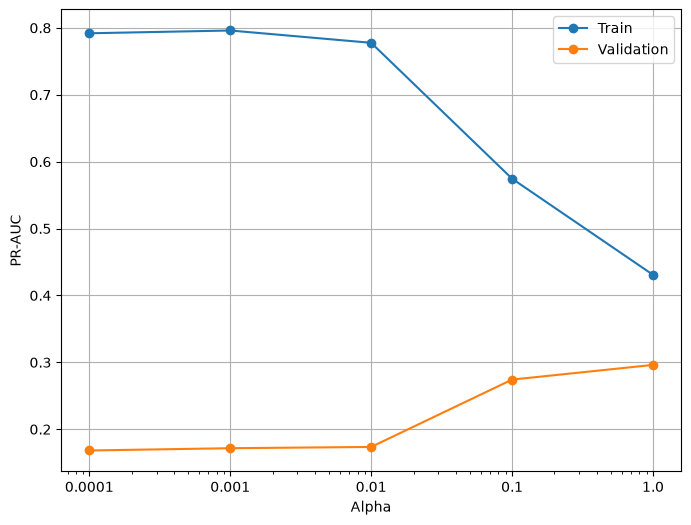

In [28]:
alphas = [0.0001, 0.001, 0.01, 0.1, 1.0]

percept_overlearn = []
# TODO: таблиця й графік PR-AUC від alpha
for alpha in alphas:
    model = MLPClassifier(hidden_layer_sizes=(32,), alpha=alpha, max_iter=1000, random_state=0)
    model.fit(X_tr, y_tr)

    train_prob = model.predict_proba(X_tr)[:, 1]
    val_prob = model.predict_proba(X_va)[:, 1]
    
    prec_auc_train = average_precision_score(y_tr, train_prob)
    prec_auc_val = average_precision_score(y_va, val_prob)

    percept_overlearn.append({"alpha": alpha,
                              "PR_AUC train": prec_auc_train,
                              "PR_AUC validate": prec_auc_val,
                              "difference": prec_auc_train - prec_auc_val
    })
percept_overlearn_df = pd.DataFrame(percept_overlearn)

display(percept_overlearn_df)

x = np.arange(len(percept_overlearn_df))
width = 0.35

plt.figure(figsize=(8,6))

plt.plot(percept_overlearn_df["alpha"], percept_overlearn_df["PR_AUC train"], marker="o", label="Train")

plt.plot(percept_overlearn_df["alpha"], percept_overlearn_df["PR_AUC validate"], marker="o", label="Validation")

plt.xscale("log")

plt.xlabel("Alpha")
plt.ylabel("PR-AUC")

plt.xticks(alphas, ["0.0001", "0.001", "0.01", "0.1", "1.0"])
plt.legend()
plt.grid()
plt.show()


## 8. Правило рішення

Модель дає ймовірність, а диспетчер має вирішити «їхати чи ні». Звичний поріг 0.5 означає «їхати, якщо відмова ймовірніша, ніж її відсутність». Але помилки коштують по-різному: зайвий виїзд — `COST_VISIT`, пропущена відмова — `COST_FAILURE`, у десятки разів дорожче. Тож виїзд виправданий і за значно меншої ймовірності.

Не поїхати до об'єкта з ймовірністю відмови p — у середньому втратити p · `COST_FAILURE`. Виїзд окупається, коли p · `COST_FAILURE` не менше за `COST_VISIT`, тобто коли p не менша за поріг `COST_VISIT / COST_FAILURE`.

Правило працює, лише якщо ймовірностям можна вірити: серед об'єктів з ймовірністю 0.1 має справді відмовляти близько 10%. Це називають **калібруванням** (calibration). Перша проста перевірка — середня ймовірність має бути близькою до частки відмов.

Ефект рішення — скільки гривень воно зберігає проти «нікого не перевіряти»:

- витрати «нікого не перевіряти» = кількість відмов · `COST_FAILURE`;
- витрати рішення = кількість виїздів · `COST_VISIT` + кількість об'єктів, що відмовили і до яких не виїхали, · `COST_FAILURE`;
- ефект = перше − друге.

1. Порахуйте поріг `COST_VISIT / COST_FAILURE` і ймовірності перцептрона з кроку 6 на `X_va`.
2. Виведіть поріг, середню ймовірність і частку відмов у `y_va`.
3. Виведіть таблицю для трьох правил — поріг з вартостей, поріг 0.5, перевірити всіх: скільки об'єктів на виїзд і ефект у гривнях. Ефект для трьох правил — одна функція від рішень, а не три копії формули. `y_va` після поділу має перемішаний індекс, тож рішення порівнюйте з `y_va.to_numpy()`.
4. Порівняйте три правила: яке зберігає найбільше і чому поріг 0.5 тут поганий — це відповідь для питання 3 звіту.

In [29]:
# TODO: поріг, ймовірності й таблиця трьох правил
threshold = COST_VISIT / COST_FAILURE

mlp = models["перцептрон"]
probability = mlp.predict_proba(X_va)[:, 1]

print("descision threshold:", threshold)
print("mean probability:", probability.mean())
print("failure part:", y_va.mean())

y_true = y_va.to_numpy()

def decider(decisions):
    visits = decisions.sum()

    missed_failures = ((decisions == 0) & (y_true == 1)).sum()

    base_cost = y_true.sum() * COST_FAILURE

    decision_cost = (visits * COST_VISIT + missed_failures * COST_FAILURE)

    return {"visit": int(visits),
            "effect hrn": int(base_cost - decision_cost)}

strategies = {"Поріг вартостей": probability >= threshold,
              "Поріг 0.5": probability >= 0.5,
              "Перевірити всіх": np.ones(len(probability), dtype=bool)}

result_cost = []

for name, decision in strategies.items():
    result = decider(decision)
    result["rule"] = name
    result_cost.append(result)

cost_df = pd.DataFrame(result_cost)

display(cost_df[["rule", "visit", "effect hrn"]])



descision threshold: 0.055
mean probability: 0.05369952129000586
failure part: 0.055776892430278883


,rule,visit,effect hrn
0,Поріг вартостей,242,1034500
1,Поріг 0.5,8,178000
2,Перевірити всіх,1004,39000


## 9. Рішення й самоперевірка

Порахуйте ймовірності перцептрона з кроку 6 на `X_te` і рішення: 1, якщо ймовірність не менша за поріг з вартостей, інакше 0. Це рішення ви здаєте: викладач порахує, скільки гривень воно зберегло б на справжніх результатах об'єктів test.

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [30]:
# TODO: рішення для test
mlp = models["перцептрон"]
test_probability = mlp.predict_proba(X_te)[:, 1]

decision = (test_probability >= threshold).astype(int)

submission = pd.DataFrame({"object_id": test["object_id"], "decision": decision})

assert (COST_VISIT, COST_FAILURE) in [(1800, 60000), (2750, 50000), (4080, 48000), (5500, 50000)], "вартості — з таблиці README"
assert all(max(a, 1 - a) <= 0.9 for a in (roc_auc_score(y, X[c]) for c in X.columns)), "в ознаках лишилася колонка з AUC понад 0.9"
assert list(X_test.columns) == list(X.columns), "колонки X_test мають збігатися з X"
assert len(X_va) == int(np.ceil(len(train) * 0.25)), "валідаційна частина — 25% train"
assert np.allclose(np.mean(X_tr, axis=0), 0) and np.allclose(np.std(X_tr, axis=0), 1), "X_tr не стандартизовано"
assert len(submission) == len(test) and submission["object_id"].is_unique, "має бути рядок на кожен об'єкт test"
assert pd.api.types.is_integer_dtype(submission["decision"]) and submission["decision"].isin([0, 1]).all(), "decision — цілі 0 або 1, а не True/False"
assert 0.02 <= submission["decision"].mean() <= 0.9, "на виїзд менше 2% або більше 90% об'єктів: перевірте поріг"

submission.to_csv("submission.csv", index=False)
print("усе гаразд: на виїзд", int(submission["decision"].sum()), "з", len(submission))

усе гаразд: на виїзд 540 з 1985
